In [3]:
import wandb

api = wandb.Api()
filters = {"tags": "kubilay-1"}
entity = "r-alvarezlucendo16"
project = "llm-memorization"
runs = list(api.runs(f"{entity}/{project}", filters))
print(f"Found {len(runs)} runs")

Found 3 runs


In [4]:
import pandas as pd

step_key = "train/global_step"
metrics = [
    "train/exact_match_repeated",
    "train/loss_repeated",
    "train/loss_random",
]

dfs = []
for run in runs:
    keys = metrics + [step_key]
    history = list(run.scan_history(keys=keys))
    meta = {"_run_id": run.id, "_run_name": run.name}
    config = dict(run.config)

    # Flatten nested config
    for key in ["dataset", "model", "training"]:
        if key in config:
            for subkey, value in config[key].items():
                meta[f"cfg.{key}.{subkey}"] = value

    # Create DataFrames and concatenate efficiently (avoid fragmentation)
    history_df = pd.DataFrame(history)
    meta_df = pd.DataFrame([meta] * len(history_df))
    df = pd.concat([history_df, meta_df], axis=1)
    dfs.append(df)

df = pd.concat(dfs, ignore_index=True)

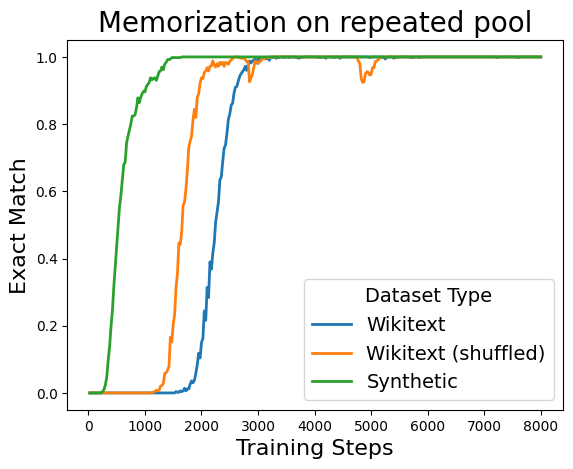

In [17]:
import matplotlib.pyplot as plt

groups = df.groupby("_run_id")[[
    "train/exact_match_repeated", 
    "train/global_step",
    "cfg.dataset._target_",
    "cfg.dataset.shuffle_fresh_pool"
]]
max_step = 8000
for ratio, group in groups:
    steps = group["train/global_step"]
    em = group["train/exact_match_repeated"]
    dataset_target = group["cfg.dataset._target_"].iloc[0]
    shuffle_fresh_pool = group["cfg.dataset.shuffle_fresh_pool"].iloc[0]

    if "WikiTextDataset" in dataset_target:
        dataset_type = "Wikitext"
        if shuffle_fresh_pool:
            dataset_type += " (shuffled)"
    elif "Synthetic" in dataset_target:
        dataset_type = "Synthetic"
    else: 
        dataset_type = "Unknown"

    steps = steps[steps <= max_step]
    em = em.iloc[: len(steps)]

    plt.plot(steps, em, label=dataset_type, linewidth=2)

plt.xlabel("Training Steps", fontsize=16)
plt.ylabel("Exact Match", fontsize=16)
plt.title("Memorization on repeated pool", fontsize=20)
plt.legend(
    title="Dataset Type", fontsize=14, title_fontsize=14, loc="lower right"
)
plt.show()

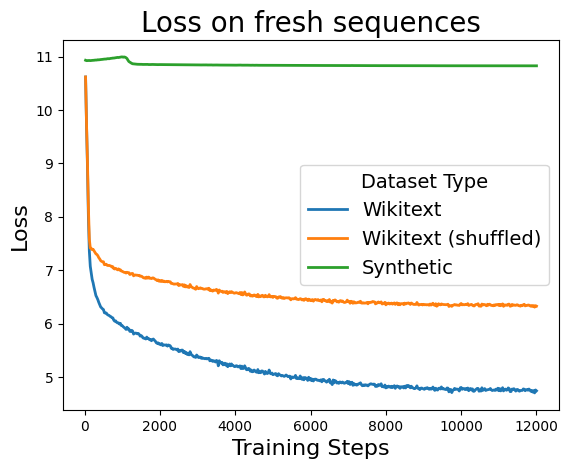

In [29]:
import matplotlib.pyplot as plt

groups = df.groupby("_run_id")[[
    "train/loss_random", 
    "train/global_step",
    "cfg.dataset._target_",
    "cfg.dataset.shuffle_fresh_pool"
]]
max_step = 20000
for ratio, group in groups:
    steps = group["train/global_step"]
    loss = group["train/loss_random"]
    dataset_target = group["cfg.dataset._target_"].iloc[0]
    shuffle_fresh_pool = group["cfg.dataset.shuffle_fresh_pool"].iloc[0]

    if "WikiTextDataset" in dataset_target:
        dataset_type = "Wikitext"
        if shuffle_fresh_pool:
            dataset_type += " (shuffled)"
    elif "Synthetic" in dataset_target:
        dataset_type = "Synthetic"
    else: 
        dataset_type = "Unknown"

    steps = steps[steps <= max_step]
    loss = loss.iloc[: len(steps)]

    plt.plot(steps, loss, label=dataset_type, linewidth=2)

plt.xlabel("Training Steps", fontsize=16)
plt.ylabel("Loss", fontsize=16)
plt.title("Loss on fresh sequences", fontsize=20)
plt.legend(
    title="Dataset Type", fontsize=14, title_fontsize=14, loc="center right"
)
plt.show()

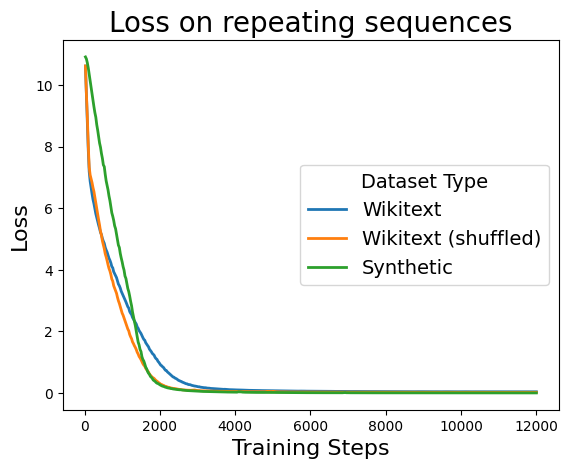

In [30]:
import matplotlib.pyplot as plt

groups = df.groupby("_run_id")[[
    "train/loss_repeated", 
    "train/global_step",
    "cfg.dataset._target_",
    "cfg.dataset.shuffle_fresh_pool"
]]
max_step = 20000
for ratio, group in groups:
    steps = group["train/global_step"]
    loss = group["train/loss_repeated"]
    dataset_target = group["cfg.dataset._target_"].iloc[0]
    shuffle_fresh_pool = group["cfg.dataset.shuffle_fresh_pool"].iloc[0]

    if "WikiTextDataset" in dataset_target:
        dataset_type = "Wikitext"
        if shuffle_fresh_pool:
            dataset_type += " (shuffled)"
    elif "Synthetic" in dataset_target:
        dataset_type = "Synthetic"
    else: 
        dataset_type = "Unknown"

    steps = steps[steps <= max_step]
    loss = loss.iloc[: len(steps)]

    plt.plot(steps, loss, label=dataset_type, linewidth=2)

plt.xlabel("Training Steps", fontsize=16)
plt.ylabel("Loss", fontsize=16)
plt.title("Loss on repeating sequences", fontsize=20)
plt.legend(
    title="Dataset Type", fontsize=14, title_fontsize=14, loc="center right"
)
plt.show()